In [1]:
import os
import sys
from PIL import Image
import numpy as np
import torch
import random
import matplotlib.pyplot as plt

sys.path.append("src")
from viper.crystal import AFMLatticeAnalysis, describe_settings

In [2]:
# Settings for AFMLatticeAnalysis class
img_file = "output/denoised/CRYS4_APO0000-HeightTrace_N2N_tuto.txt" # Input file
out_path = "output/autocorr"                                        # Output path
fov_nm = 100.0                                                      # Field of View size
label = "AFM"                                                       # Data label

# Initialize AFMLatticeAnalysis class
ana = AFMLatticeAnalysis(
    file=img_file, output_dir=out_path, fov_nm=fov_nm, data_label=label
)

In [3]:
# Common Analysis Settings 
ana.settings.max_acf_vectors_for_lattice = 30
ana.settings.max_fft_vectors_for_lattice = 25
ana.settings.max_acf_peaks = 80
ana.settings.max_fft_peaks = 30
ana.settings.acf_threshold_sigma = 2.5
ana.settings.fft_threshold_sigma = 4.5

# For full settings description, please uncomment:
# describe_settings()

In [4]:
# Process and make the comparison
ana.load()                 # Load input
ana.run_fft()              # Run FFT
pfft = ana.paired_fft      # FFT periodicities (freq space)
ana.run_autocorrelation()  # Run autocorrelation (real space)
ana.find_lattice()         # Compare FFT and ACF and find lattice
lattice = ana.lattice      # v1, v2, beta, coverage, etc...

Loaded CRYS4_APO0000-HeightTrace_N2N_tuto.txt: 256 x 256 grid, dx=0.392157 nm, dy=0.392157 nm, FOV=100.392 x 100.392 nm


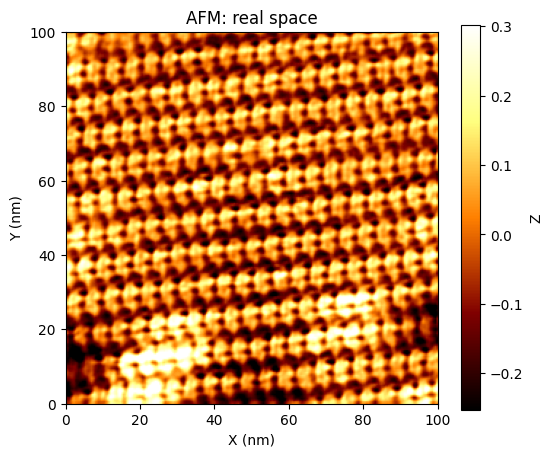

In [5]:
# Plot real space image
_ = ana.plot_real_space()

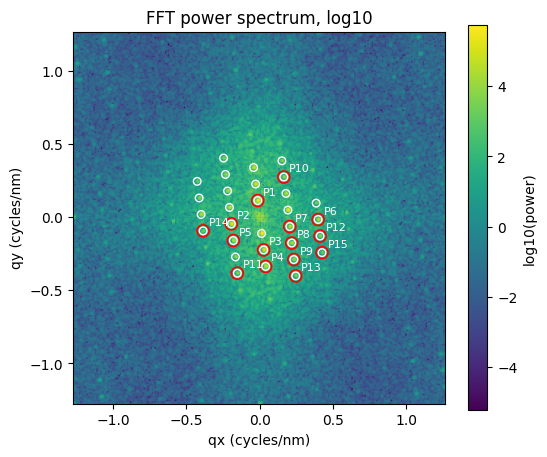

In [6]:
# Plot FFT image
_ = ana.plot_fft()

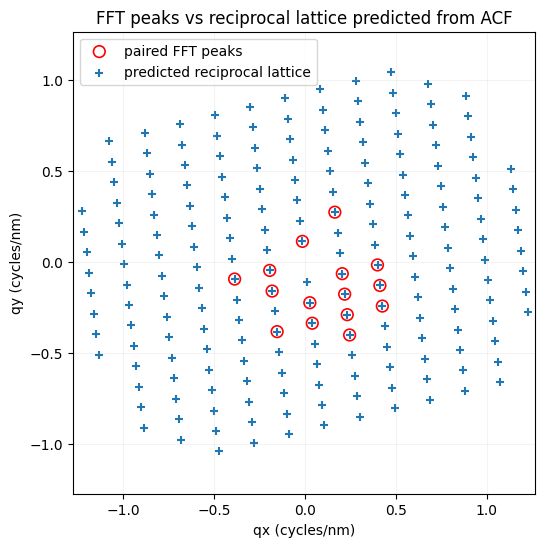

In [7]:
# plot FFT peaks vs predicted from ACF
_ = ana.plot_fft_reciprocal_lattice()

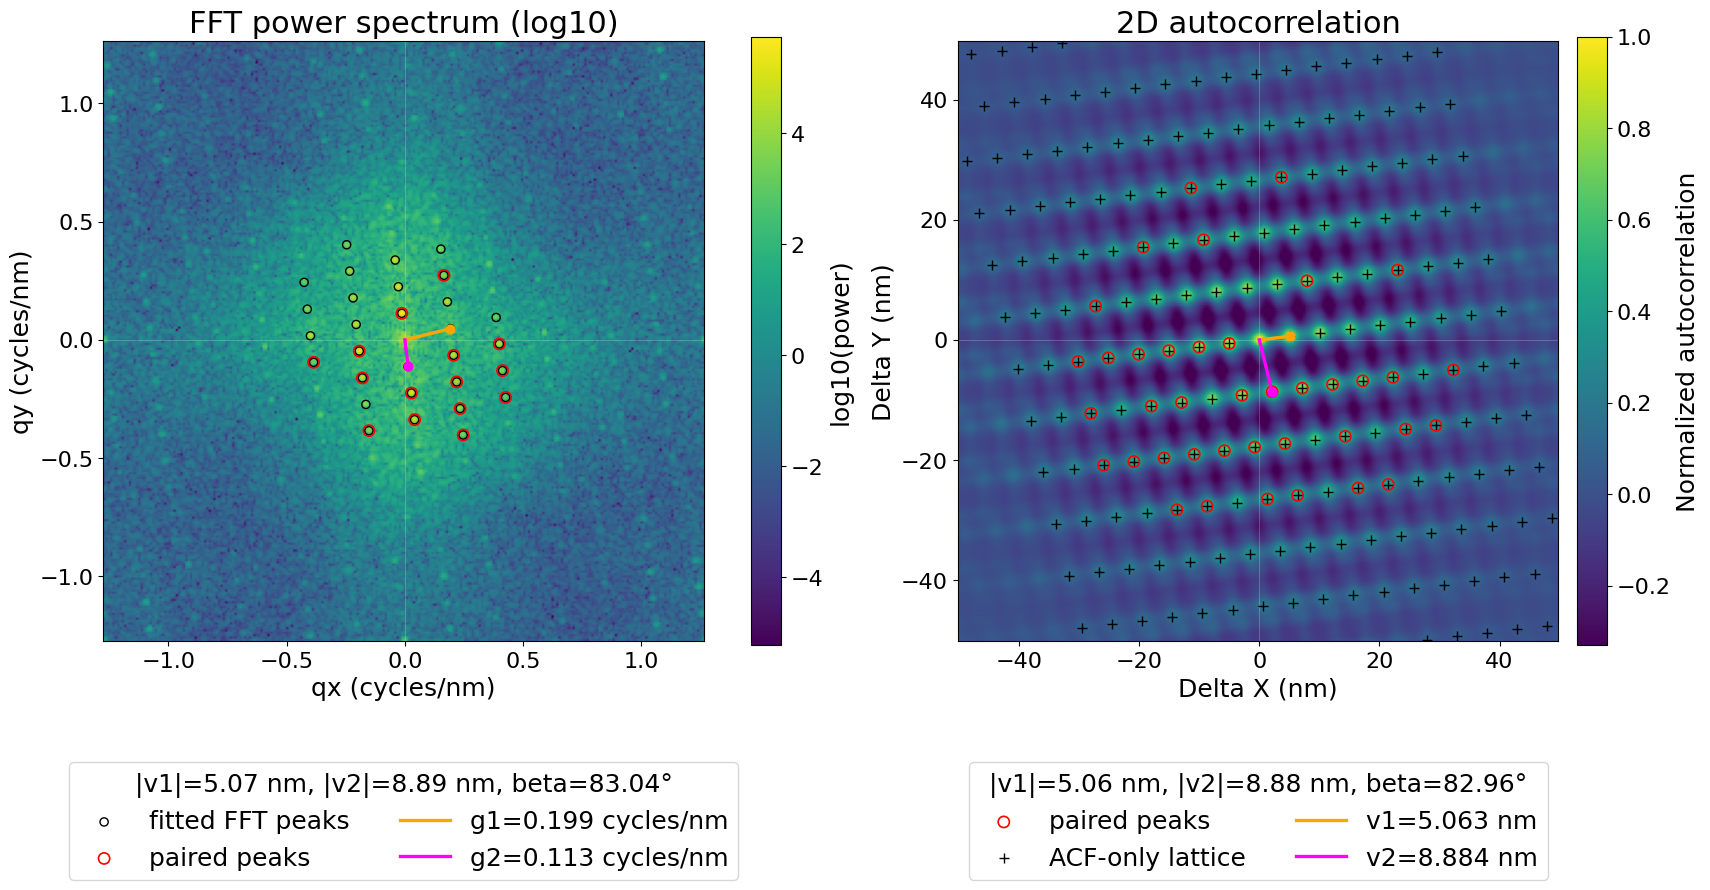

In [9]:
# plot FFT peaks vs predicted from ACF
_ = ana.plot_fft_vs_acf(
    title_size=22, label_size=18,
    tick_size=16, legend_size=18
)

In [ ]:
# Save all results
ana.save_all()